In [1]:
# Import libraries
import os, random, time, copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report
from PIL import Image

# Set seed and device
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Find dataset folder
DATA_PATH = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'Arborio' in dirs:
        DATA_PATH = root
        break
print("Dataset path:", DATA_PATH)

Using device: cuda
Dataset path: /kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset


##Load and Explore the Dataset

**Dataset:**
- **75,000 RGB images** (250×250 px, JPEG) of single grains on a black background.
- **5 balanced classes** (15,000 per class): **Arborio, Basmati, Ipsala, Jasmine, Karacadag**, loaded via `ImageFolder`.

Classes: ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
Total images: 75000
Arborio: 15000
Basmati: 15000
Ipsala: 15000
Jasmine: 15000
Karacadag: 15000
Image size: (250, 250) | Mode: RGB


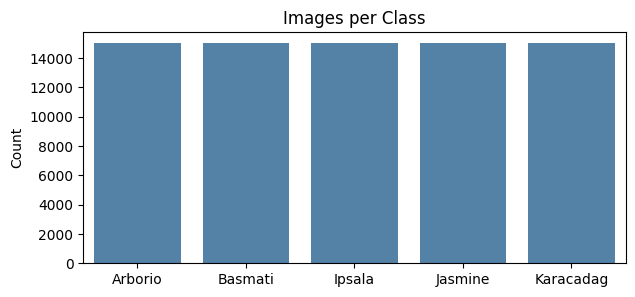

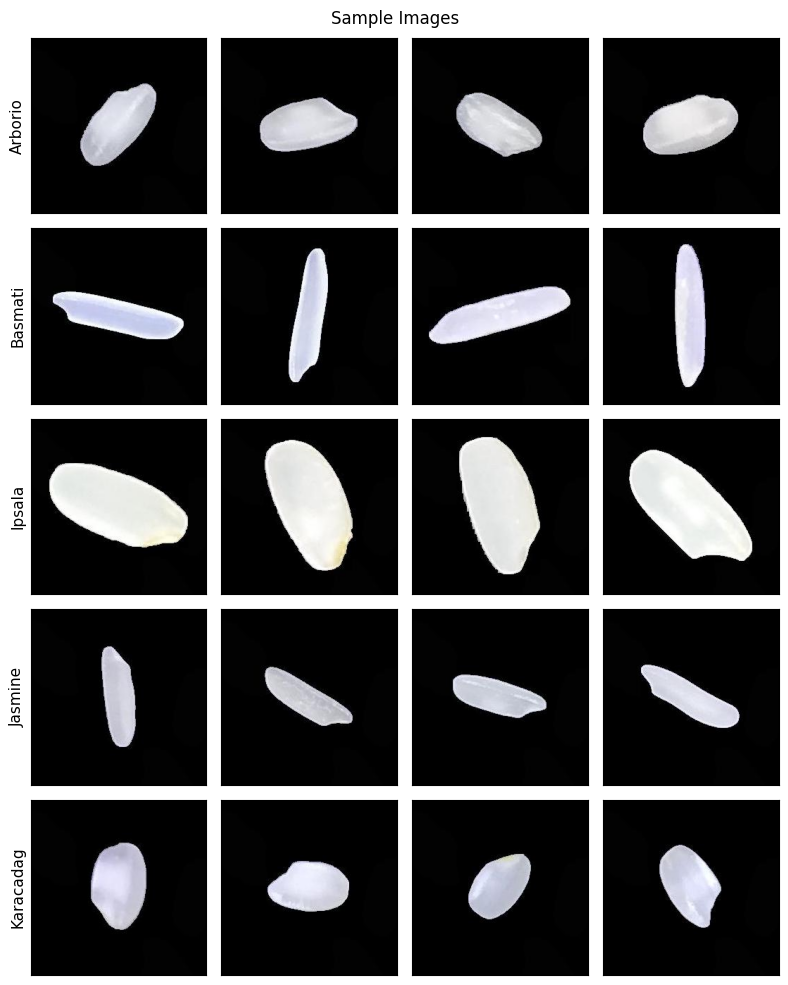

In [2]:
# Load full dataset to check classes
full_ds = datasets.ImageFolder(root=DATA_PATH)
class_names = full_ds.classes
num_classes = len(class_names)
targets = np.array(full_ds.targets)

print("Classes:", class_names)
print("Total images:", len(full_ds))

# Images per class
counts = np.bincount(targets, minlength=num_classes)
for name, c in zip(class_names, counts):
    print(f"{name}: {c}")

sample_img = Image.open(full_ds.samples[0][0])
print("Image size:", sample_img.size, "| Mode:", sample_img.mode)

# Class distribution plot
plt.figure(figsize=(7, 3))
sns.barplot(x=class_names, y=counts, color='steelblue')
plt.title('Images per Class')
plt.ylabel('Count')
plt.show()

# Sample images from each class
fig, axes = plt.subplots(num_classes, 4, figsize=(8, 10))
for ci, name in enumerate(class_names):
    idxs = np.random.choice(np.where(targets == ci)[0], 4, replace=False)
    for j, idx in enumerate(idxs):
        ax = axes[ci, j]
        ax.imshow(Image.open(full_ds.samples[idx][0]))
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(name, fontsize=11)
plt.suptitle('Sample Images')
plt.tight_layout()
plt.show()

Train: 7000, Val: 1500, Test: 1500
Batch shape: torch.Size([64, 3, 64, 64])


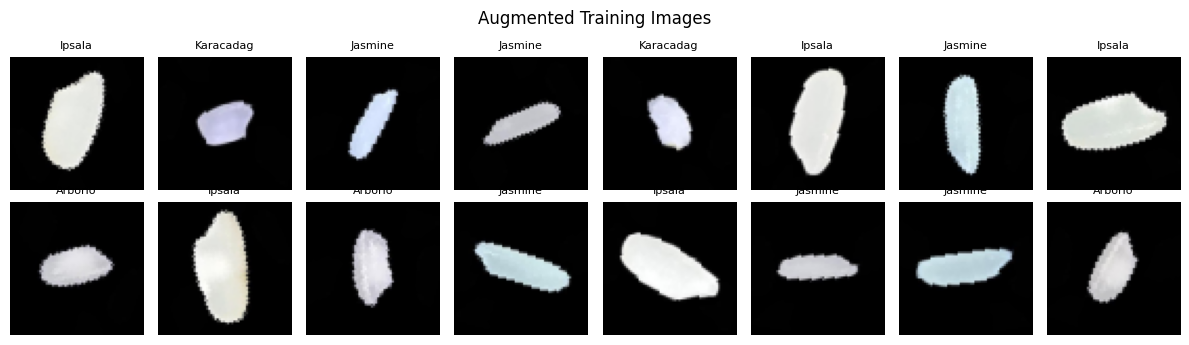

In [3]:
# Define core variables
SAMPLES_PER_CLASS = 2000
IMG_SIZE = 64
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
EPOCHS = 15

# Take 2000 images per class and split 70/15/15
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []
for ci in range(num_classes):
    idxs = rng.choice(np.where(targets == ci)[0], SAMPLES_PER_CLASS, replace=False)
    n_tr = int(0.70 * SAMPLES_PER_CLASS)
    n_va = int(0.15 * SAMPLES_PER_CLASS)
    train_idx += idxs[:n_tr].tolist()
    val_idx += idxs[n_tr:n_tr + n_va].tolist()
    test_idx += idxs[n_tr + n_va:].tolist()
print(f"Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}")

normalize = transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])

# Augmented transform for training
aug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ToTensor(),
    normalize
])

# Basic transform (No Augmentation) for validation and test
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    normalize
])

ds_aug = datasets.ImageFolder(DATA_PATH, transform=aug_transform)
ds_basic = datasets.ImageFolder(DATA_PATH, transform=basic_transform)

# Data loaders
train_loader = DataLoader(Subset(ds_aug, train_idx), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(Subset(ds_basic, val_idx), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_data = Subset(ds_basic, test_idx)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

x, y = next(iter(train_loader))
print("Batch shape:", x.shape)

# Eyeball the augmented training data
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    img = x[i].permute(1, 2, 0) * 0.5 + 0.5
    ax.imshow(img.clamp(0, 1))
    ax.set_title(class_names[y[i]], fontsize=8)
    ax.axis('off')
plt.suptitle('Augmented Training Images')
plt.tight_layout()
plt.show()

In [4]:
class RiceCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        def conv_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2)
            )

        # Feature extraction
        self.features = nn.Sequential(
            conv_block(3, 32),     # 64 -> 32
            conv_block(32, 64),    # 32 -> 16
            conv_block(64, 128)    # 16 -> 8
        )

        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = RiceCNN(num_classes).to(device)
print(model)

# Model summary
!pip install -q torchsummary
from torchsummary import summary
summary(model, input_size=(3, IMG_SIZE, IMG_SIZE))

RiceCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(

In [5]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

def train_one_epoch(loader, model, loss_fn, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(loader, model, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += loss_fn(out, y).item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total

history_r2 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss, best_epoch = float('inf'), 0

print("Starting Round 2 Training (Robust Model)...")
start = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(train_loader, model, loss_fn, optimizer)
    va_loss, va_acc = evaluate(val_loader, model, loss_fn)
    scheduler.step(va_loss)

    history_r2['train_loss'].append(tr_loss)
    history_r2['train_acc'].append(tr_acc)
    history_r2['val_loss'].append(va_loss)
    history_r2['val_acc'].append(va_acc)

    # Save best model
    if va_loss < best_val_loss:
        best_val_loss, best_epoch = va_loss, epoch
        best_weights = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch} | Train Acc: {tr_acc:.4f} | Val Acc: {va_acc:.4f} | Val Loss: {va_loss:.4f}")

print(f"Training time: {(time.time() - start)/60:.1f} min | Best epoch: {best_epoch}")
model.load_state_dict(best_weights);

Starting Round 2 Training (Robust Model)...
Epoch 1 | Train Acc: 0.8466 | Val Acc: 0.9080 | Val Loss: 0.2220
Epoch 2 | Train Acc: 0.9666 | Val Acc: 0.9833 | Val Loss: 0.0491
Epoch 3 | Train Acc: 0.9757 | Val Acc: 0.9960 | Val Loss: 0.0175
Epoch 4 | Train Acc: 0.9763 | Val Acc: 0.9687 | Val Loss: 0.0777
Epoch 5 | Train Acc: 0.9777 | Val Acc: 0.8607 | Val Loss: 0.4786
Epoch 6 | Train Acc: 0.9759 | Val Acc: 0.9727 | Val Loss: 0.0745
Epoch 7 | Train Acc: 0.9849 | Val Acc: 0.9940 | Val Loss: 0.0134
Epoch 8 | Train Acc: 0.9881 | Val Acc: 0.9913 | Val Loss: 0.0210
Epoch 9 | Train Acc: 0.9900 | Val Acc: 0.9953 | Val Loss: 0.0143
Epoch 10 | Train Acc: 0.9881 | Val Acc: 0.9960 | Val Loss: 0.0101
Epoch 11 | Train Acc: 0.9909 | Val Acc: 0.9880 | Val Loss: 0.0356
Epoch 12 | Train Acc: 0.9869 | Val Acc: 0.9833 | Val Loss: 0.0542
Epoch 13 | Train Acc: 0.9906 | Val Acc: 0.9947 | Val Loss: 0.0181
Epoch 14 | Train Acc: 0.9919 | Val Acc: 0.9967 | Val Loss: 0.0098
Epoch 15 | Train Acc: 0.9937 | Val Acc: 0

In [6]:
# Training data without augmentation
train_loader_r1 = DataLoader(Subset(ds_basic, train_idx), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

# Same model, NO DROPOUT IN ROUND 1
torch.manual_seed(SEED)
model_r1 = RiceCNN(num_classes)
model_r1.classifier[3] = nn.Identity()
model_r1 = model_r1.to(device)

optimizer_r1 = torch.optim.Adam(model_r1.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler_r1 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_r1, mode='min', factor=0.5, patience=2)

history_r1 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print("Starting Round 1 Training (Baseline)...")
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(train_loader_r1, model_r1, loss_fn, optimizer_r1)
    va_loss, va_acc = evaluate(val_loader, model_r1, loss_fn)
    scheduler_r1.step(va_loss)

    history_r1['train_loss'].append(tr_loss)
    history_r1['train_acc'].append(tr_acc)
    history_r1['val_loss'].append(va_loss)
    history_r1['val_acc'].append(va_acc)

    print(f"Epoch {epoch} | Train Acc: {tr_acc:.4f} | Val Acc: {va_acc:.4f} | Val Loss: {va_loss:.4f}")

# Train-val gap at the last epoch
print()
for name, h in [('Round 1', history_r1), ('Round 2', history_r2)]:
    gap = (h['train_acc'][-1] - h['val_acc'][-1]) * 100
    print(f"{name} | Train Acc: {h['train_acc'][-1]:.4f} | Val Acc: {h['val_acc'][-1]:.4f} | Gap: {gap:+.2f}%")

Starting Round 1 Training (Baseline)...
Epoch 1 | Train Acc: 0.8643 | Val Acc: 0.9767 | Val Loss: 0.0765
Epoch 2 | Train Acc: 0.9850 | Val Acc: 0.9887 | Val Loss: 0.0366
Epoch 3 | Train Acc: 0.9857 | Val Acc: 0.9827 | Val Loss: 0.0464
Epoch 4 | Train Acc: 0.9866 | Val Acc: 0.9593 | Val Loss: 0.0999
Epoch 5 | Train Acc: 0.9877 | Val Acc: 0.2627 | Val Loss: 35.8268
Epoch 6 | Train Acc: 0.9896 | Val Acc: 0.9960 | Val Loss: 0.0134
Epoch 7 | Train Acc: 0.9937 | Val Acc: 0.9967 | Val Loss: 0.0111
Epoch 8 | Train Acc: 0.9940 | Val Acc: 0.9960 | Val Loss: 0.0159
Epoch 9 | Train Acc: 0.9964 | Val Acc: 0.9973 | Val Loss: 0.0088
Epoch 10 | Train Acc: 0.9977 | Val Acc: 0.9933 | Val Loss: 0.0163
Epoch 11 | Train Acc: 0.9987 | Val Acc: 0.9927 | Val Loss: 0.0170
Epoch 12 | Train Acc: 0.9980 | Val Acc: 0.9953 | Val Loss: 0.0156
Epoch 13 | Train Acc: 0.9983 | Val Acc: 0.9967 | Val Loss: 0.0089
Epoch 14 | Train Acc: 0.9991 | Val Acc: 0.9960 | Val Loss: 0.0086
Epoch 15 | Train Acc: 1.0000 | Val Acc: 0.99

Round 2 (Robust)   | Test Loss: 0.0296 | Test Acc: 99.13%
Round 1 (Baseline) | Test Loss: 0.0287 | Test Acc: 99.53%

              precision    recall  f1-score   support

     Arborio     1.0000    0.9833    0.9916       300
     Basmati     1.0000    0.9733    0.9865       300
      Ipsala     1.0000    1.0000    1.0000       300
     Jasmine     0.9677    1.0000    0.9836       300
   Karacadag     0.9901    1.0000    0.9950       300

    accuracy                         0.9913      1500
   macro avg     0.9916    0.9913    0.9913      1500
weighted avg     0.9916    0.9913    0.9913      1500



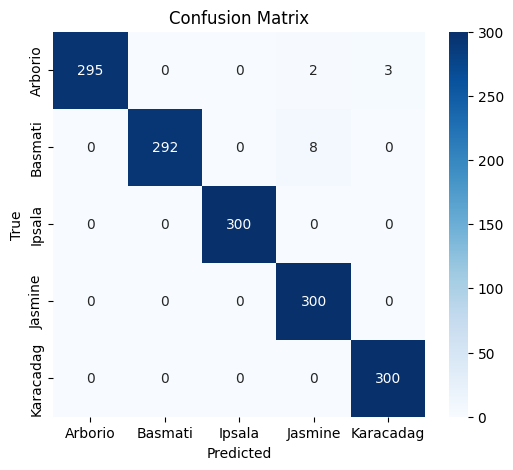

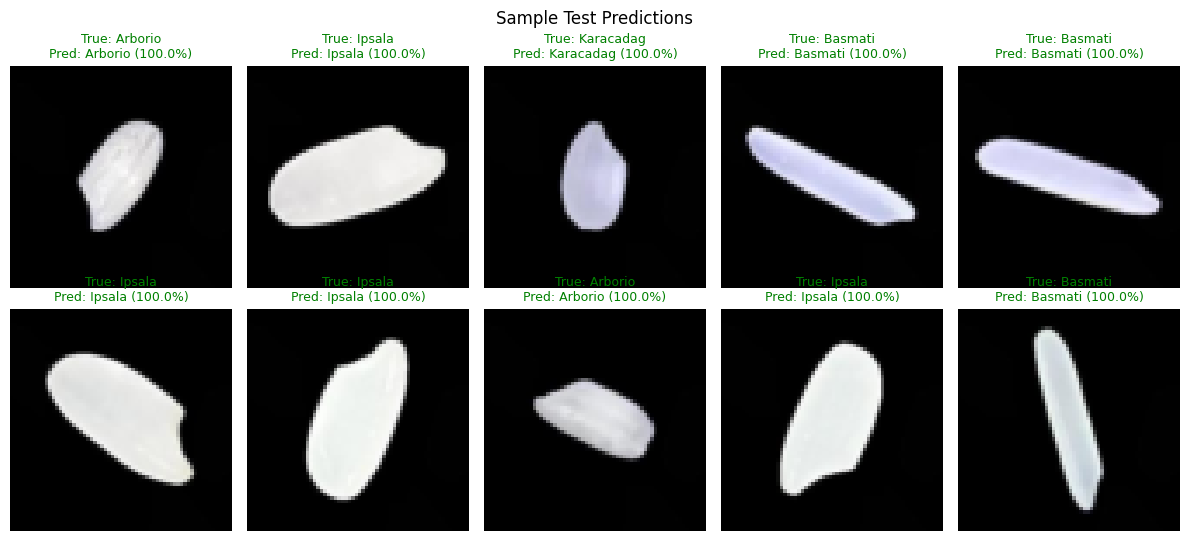

Misclassified: 13 / 1500


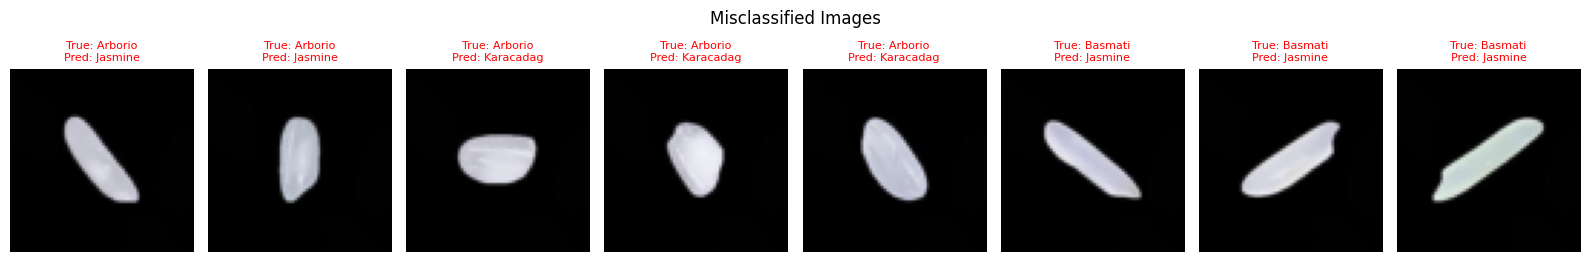

In [7]:
# Test accuracy
test_loss, test_acc = evaluate(test_loader, model, loss_fn)
test_loss_r1, test_acc_r1 = evaluate(test_loader, model_r1, loss_fn)
print(f"Round 2 (Robust)   | Test Loss: {test_loss:.4f} | Test Acc: {test_acc*100:.2f}%")
print(f"Round 1 (Baseline) | Test Loss: {test_loss_r1:.4f} | Test Acc: {test_acc_r1*100:.2f}%")

# Get predictions on test set
model.eval()
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        probs = torch.softmax(outputs, dim=1)
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(probs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())
all_preds, all_labels, all_probs = np.array(all_preds), np.array(all_labels), np.array(all_probs)

# Classification report
print()
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

def to_img(t):
    return (t.permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1).numpy()

# Sample predictions
idxs = np.random.choice(len(test_data), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, i in zip(axes.flat, idxs):
    img, label = test_data[i]
    pred = all_preds[i]
    conf = all_probs[i].max() * 100
    color = 'green' if pred == label else 'red'
    ax.imshow(to_img(img))
    ax.set_title(f"True: {class_names[label]}\nPred: {class_names[pred]} ({conf:.1f}%)", fontsize=9, color=color)
    ax.axis('off')
plt.suptitle('Sample Test Predictions')
plt.tight_layout()
plt.show()

# Misclassified images
wrong = np.where(all_preds != all_labels)[0]
print(f"Misclassified: {len(wrong)} / {len(all_labels)}")
if len(wrong) > 0:
    n = min(len(wrong), 8)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.8), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        img, _ = test_data[i]
        ax.imshow(to_img(img))
        ax.set_title(f"True: {class_names[all_labels[i]]}\nPred: {class_names[all_preds[i]]}", fontsize=8, color='red')
        ax.axis('off')
    plt.suptitle('Misclassified Images')
    plt.tight_layout()
    plt.show()

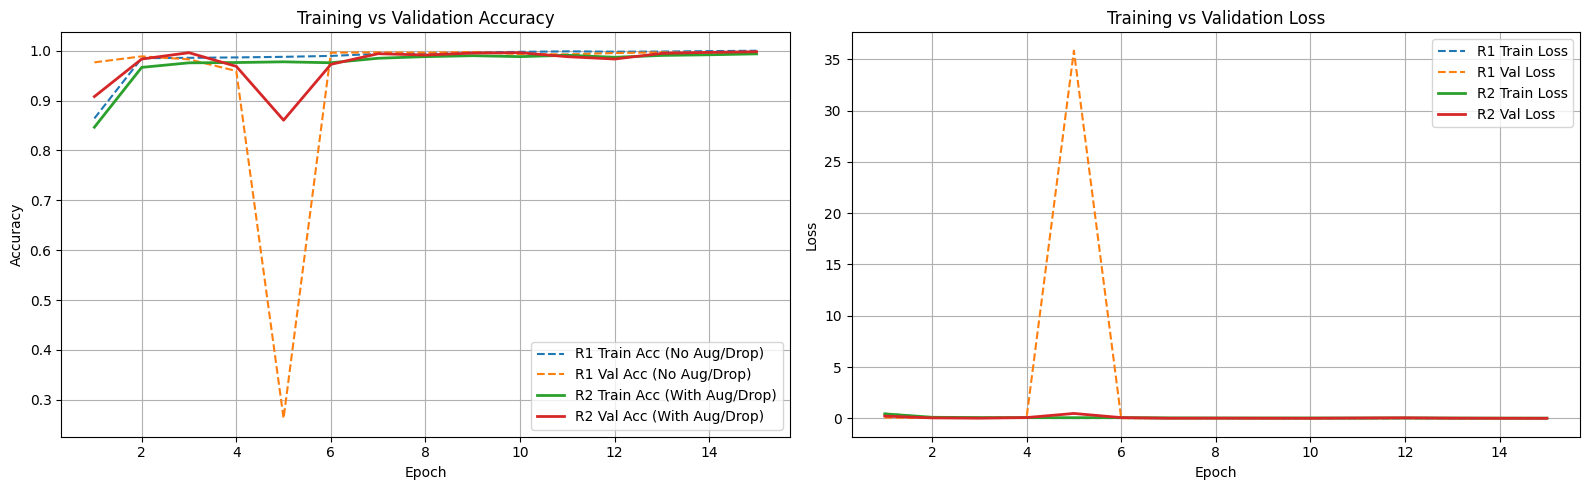

In [8]:
epochs = range(1, EPOCHS + 1)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

# Accuracy Plot
axs[0].plot(epochs, history_r1['train_acc'], label='R1 Train Acc (No Aug/Drop)', linestyle='--')
axs[0].plot(epochs, history_r1['val_acc'], label='R1 Val Acc (No Aug/Drop)', linestyle='--')
axs[0].plot(epochs, history_r2['train_acc'], label='R2 Train Acc (With Aug/Drop)', linewidth=2)
axs[0].plot(epochs, history_r2['val_acc'], label='R2 Val Acc (With Aug/Drop)', linewidth=2)
axs[0].set_title('Training vs Validation Accuracy')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Accuracy')
axs[0].legend()
axs[0].grid(True)

# Loss Plot
axs[1].plot(epochs, history_r1['train_loss'], label='R1 Train Loss', linestyle='--')
axs[1].plot(epochs, history_r1['val_loss'], label='R1 Val Loss', linestyle='--')
axs[1].plot(epochs, history_r2['train_loss'], label='R2 Train Loss', linewidth=2)
axs[1].plot(epochs, history_r2['val_loss'], label='R2 Val Loss', linewidth=2)
axs[1].set_title('Training vs Validation Loss')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Loss')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

###  Save and Reload the Trained Model

Saves the trained `state_dict` to `/kaggle/working/rice_cnn_model.pth`, reloads it into a fresh `RiceCNN` instance, and verifies that test accuracy matches.

In [9]:
# Save model weights
MODEL_PATH = '/kaggle/working/rice_cnn_model.pth'
torch.save(model.state_dict(), MODEL_PATH)
print(f"Model saved: {MODEL_PATH} ({os.path.getsize(MODEL_PATH)/1e6:.2f} MB)")

# Load model and check it works
loaded_model = RiceCNN(num_classes).to(device)
loaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=devi
                                        ce))
loaded_model.eval()
_, loaded_acc = evaluate(test_loader, loaded_model, loss_fn)
print(f"Loaded model test accuracy: {loaded_acc*100:.2f}%")

Model saved: /kaggle/working/rice_cnn_model.pth (8.78 MB)
Loaded model test accuracy: 99.13%


## 8. Analysis & Discussion of Results

On the 1,500 test images, our final model (Round 2) got 99.13% accuracy with a test loss of 0.0296 and a macro F1-score of 0.9913. Ipsala, Jasmine, and Karacadag all had 100% recall, and Ipsala had zero mistakes because it is the largest and widest grain in the dataset.

Out of 1,500 test images, the model only misclassified 13 images. Specifically, 8 Basmati images were predicted as Jasmine, 3 Arborio images were predicted as Karacadag, and 2 Arborio images were predicted as Jasmine. This happens because Basmati and Jasmine are both long and thin grains, while Arborio and Karacadag are both short and round. After resizing the images from 250x250 down to 64x64, the small differences at the tips of the grains get slightly blurry.

When comparing Round 1 (without augmentation and dropout) and Round 2 (with augmentation and dropout), Round 1 reached 100.00% training accuracy and 99.60% validation accuracy (+0.40% gap), showing that it memorized the training images. Round 1 was also very unstable during training, dropping to 26.27% validation accuracy (validation loss 35.8268) at Epoch 5. In Round 2, the final training accuracy was 99.37% and validation accuracy was 99.80% (-0.43% gap), and at Epoch 5 the validation accuracy stayed much higher at 86.07% (validation loss 0.4786). Even though Round 1 got a slightly higher test accuracy (99.53% vs 99.13%) because the dataset has clean black backgrounds, Round 2 trained much more smoothly without overfitting.

## 9. Conclusions & Future Work

In this assignment, we built a 3-block CNN from scratch with 2.19M parameters (8.78 MB) to classify 5 types of rice grains and achieved 99.13% test accuracy. Using data augmentation, dropout (0.5), batch normalization, and the ReduceLROnPlateau learning rate scheduler helped stop the model from overfitting and prevented large validation loss spikes during training. We also saved the trained weights to rice_cnn_model.pth and reloaded them into a new model instance, which gave the exact same 99.13% test accuracy.

There are a few limitations in our current setup. First, we used 10,000 images (2,000 per class) instead of all 75,000 images so that training would finish faster on Kaggle. Second, resizing the images to 64x64 removed some fine grain details, which caused a few mix-ups between Basmati and Jasmine. Third, all images in this dataset have a plain black background with a single grain, so the model might struggle if tested on real-world phone photos.

In the future, we can train the model on all 75,000 images at a higher resolution like 128x128 to reduce the confusion between Basmati and Jasmine. We can also compare our custom CNN with pretrained models like ResNet-18, use k-fold cross-validation, and test the model on real camera photos.